In [1]:
import sys
project_root = "../.."
sys.path.append(project_root)

import numpy as np
import seaborn as sns
import torch
from IPython.display import HTML

# Import project packages
from src.simulation.visualization.animation import create_animation_1d
from src.simulation.equations.burgers1d import BurgersEquation1D

device = torch.device("cpu")
sns.set_style("ticks")
sns.set_context("paper")

In [2]:
eq = BurgersEquation1D(
    L=1.0,
    T=1.0,
    n_x=100,
    n_t=100,
    viscosity={"type": "constant", "value": 0.01},
    ic={"type":"grf", "ell": 0.08, "std": 1.0, "mean":0.0,  "normalize": True},
    bc={"type":"Periodic"},
    CFL=0.5,
    second_order=True,
)


snapshots = eq.solve()

frames = [[snapshots[i] for i in range(len(snapshots))]]
labels = ["gt"]
animation = create_animation_1d(frames, labels, y_lim_min=-1.0, y_lim_max=1)
HTML(animation.to_html5_video())

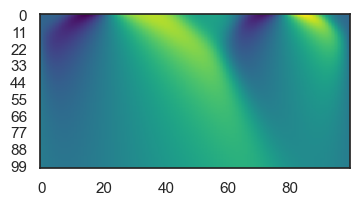

In [3]:
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(4, 2))
ax.imshow(snapshots, cmap="viridis", aspect="auto")
ax.set_yticks(np.arange(0, snapshots.shape[0], 11))
plt.show()
